# Predição de lesões em corredores competitivos com Aprendizado de Máquina

**Disciplina:** Aprendizado de Máquina para Saúde — Projeto de Aplicação

**Aluno:** Gabriel Abreu Alves da Silva e Silva

**Objetivo.** Estimar, a partir do log de treinamento dos dias/semanas anteriores, a probabilidade de um atleta sofrer uma lesão, comparando modelos de diferentes complexidades (baseline, regressão logística, Random Forest, XGBoost, XGBoost *bagged* com subamostragem — inspirado em Lövdal et al., 2021 — e uma rede neural MLP).

**Dataset.** *Replication Data for: Injury Prediction in Competitive Runners With Machine Learning* (Lövdal, Den Hartigh & Azzopardi, 2021) — DataverseNL, DOI [10.34894/UWU9PV](https://doi.org/10.34894/UWU9PV). Log de treino de 74 corredores de meia e longa distância de uma equipe holandesa de alto nível (2012–2019).

| Abordagem | Arquivo | Entrada (X) | Saída (y) |
|---|---|---|---|
| Dia | `day_approach_maskedID_timeseries.csv` | 10 variáveis de carga/percepção × 7 dias anteriores | lesão (0/1) |
| Semana | `week_approach_maskedID_timeseries.csv` | 22 variáveis agregadas × 3 semanas anteriores | lesão (0/1) |

**Unidade de análise:** um dia-atleta (abordagem dia) ou uma semana-atleta (abordagem semana).
**Tarefa:** classificação binária fortemente desbalanceada.

> Estrutura do notebook (conforme instruções da entrega):
> 1. Dependências do ambiente de execução
> 2. Etapas de execução — bibliotecas, funções de apoio, carregamento/pré-processamento, hiperparâmetros
> 3. Execução — curvas por iteração e medidas de desempenho

## 1. Dependências do ambiente de execução

O notebook foi feito para rodar no **Google Colab** (CPU é suficiente). As bibliotecas abaixo já vêm instaladas no Colab; a célula apenas garante o `xgboost` e registra as versões usadas, para reprodutibilidade.

| Pacote | Uso |
|---|---|
| `numpy`, `pandas` | manipulação dos dados |
| `scikit-learn` | pré-processamento, modelos clássicos, métricas, divisão agrupada |
| `xgboost` | gradient boosting |
| `torch` | rede neural MLP |
| `matplotlib` | gráficos |

In [37]:
# Instala o xgboost caso não esteja presente (no Colab normalmente já está)
import importlib, subprocess, sys
for pkg in ["xgboost"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import platform, numpy, pandas, sklearn, xgboost, torch, matplotlib
print(f"Python       {platform.python_version()}")
for m in [numpy, pandas, sklearn, xgboost, torch, matplotlib]:
    print(f"{m.__name__:<12} {m.__version__}")
print("GPU disponível:", torch.cuda.is_available())

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
sklearn      1.6.1
xgboost      3.4.1
torch        2.14.1+cpu
matplotlib   3.10.0
GPU disponível: False


## 2. Etapas de execução

### 2.1 Bibliotecas utilizadas

In [38]:
import os, re, json, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix,
                             f1_score, precision_score, recall_score)

import xgboost as xgb
import torch
import torch.nn as nn

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# Estilo dos gráficos — paleta categórica em ordem fixa (cada modelo sempre com a mesma cor)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#008300", "#e34948"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "font.size": 10,
})

### 2.2 Funções de apoio

- `set_seed` — fixa as sementes (reprodutibilidade).
- `find_col` — localiza colunas de id do atleta / data / rótulo independentemente de maiúsculas e espaços.
- `athlete_normalize` — padronização *z-score* de cada variável **por atleta** (cada corredor comparado com o próprio histórico, como em Lövdal et al.). Não usa o rótulo.
- `group_split` — divisão estratificada **por atleta** (nenhum atleta aparece em mais de um conjunto → evita *data leakage* entre treino e teste).
- `youden_threshold` — escolhe o limiar de decisão que maximiza *sensibilidade + especificidade − 1* no conjunto de validação.
- `evaluate` — calcula as medidas de desempenho.
- `cluster_bootstrap_ci` — intervalo de confiança de 95% por *bootstrap* reamostrando **atletas** (respeita a dependência entre observações do mesmo atleta).
- `BaggedXGB` — ensemble de XGBoost com subamostragem da classe negativa em cada *bag* (estratégia de Lövdal et al., 2021).
- `MLP` / `train_mlp` — rede neural em PyTorch com registro de perda e AUROC/AUPRC por época.

In [39]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)


def find_col(df, candidates):
    norm = {re.sub(r"[^a-z]", "", c.lower()): c for c in df.columns}
    for cand in candidates:
        key = re.sub(r"[^a-z]", "", cand.lower())
        if key in norm:
            return norm[key]
    return None


def athlete_normalize(df, feature_cols, group_col, eps=1e-6):
    # z-score de cada variável usando média e desvio-padrão do próprio atleta.
    g = df.groupby(group_col)[feature_cols]
    mu, sd = g.transform("mean"), g.transform("std").fillna(0)
    out = df.copy()
    out[feature_cols] = (df[feature_cols] - mu) / (sd + eps)
    return out


def group_split(y, groups, n_splits, seed):
    # Retorna (idx_restante, idx_separado) com ~1/n_splits dos atletas separados, estratificado pelo rótulo.
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return next(sgkf.split(np.zeros(len(y)), y, groups))

def threshold_at_specificity(y_true, proba, spec):
    # Limiar tal que uma fração `spec` dos negativos fica abaixo dele (especificidade-alvo).
    return float(np.quantile(np.asarray(proba)[np.asarray(y_true) == 0], spec))


def youden_threshold(y_true, proba):
    fpr, tpr, thr = roc_curve(y_true, proba)
    return float(thr[np.argmax(tpr - fpr)])


def evaluate(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "AUROC": roc_auc_score(y_true, proba),
        "AUPRC": average_precision_score(y_true, proba),
        "Lift AUPRC": average_precision_score(y_true, proba) / np.mean(y_true),
        "Limiar": thr,
        "Sensibilidade": tp / (tp + fn) if tp + fn else np.nan,
        "Especificidade": tn / (tn + fp) if tn + fp else np.nan,
        "Precisão (VPP)": precision_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


def cluster_bootstrap_ci(y_true, proba, groups, metric, n_boot=1000, seed=0):
    # IC 95% reamostrando atletas com reposição.
    rng = np.random.default_rng(seed)
    y_true, proba, groups = np.asarray(y_true), np.asarray(proba), np.asarray(groups)
    uniq = np.unique(groups)
    idx_by_g = {g: np.where(groups == g)[0] for g in uniq}
    stats = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_g[g] for g in rng.choice(uniq, size=len(uniq), replace=True)])
        if y_true[idx].min() == y_true[idx].max():
            continue
        stats.append(metric(y_true[idx], proba[idx]))
    return np.percentile(stats, [2.5, 97.5])


class BaggedXGB:
    # Ensemble de XGBoost: cada bag usa todos os positivos + amostra aleatória de negativos.
    def __init__(self, n_bags, neg_pos_ratio, xgb_params, seed=0):
        self.n_bags, self.ratio, self.params, self.seed = n_bags, neg_pos_ratio, xgb_params, seed
        self.models = []

    def fit(self, X, y, X_val=None, y_val=None):
        rng = np.random.default_rng(self.seed)
        pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
        n_neg = min(len(neg), int(self.ratio * len(pos)))
        self.history = []                      # AUROC/AUPRC de validação à medida que bags são adicionadas
        val_sum = np.zeros(len(y_val)) if X_val is not None else None
        for b in range(self.n_bags):
            idx = np.concatenate([pos, rng.choice(neg, n_neg, replace=False)])
            m = xgb.XGBClassifier(**self.params, random_state=self.seed + b)
            m.fit(X[idx], y[idx])
            self.models.append(m)
            if X_val is not None:
                val_sum += m.predict_proba(X_val)[:, 1]
                p = val_sum / (b + 1)
                self.history.append((b + 1, roc_auc_score(y_val, p), average_precision_score(y_val, p)))
        return self

    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.models], axis=0)
        return np.column_stack([1 - p, p])


class MLP(nn.Module):
    def __init__(self, n_in, hidden, dropout):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def predict_mlp(model, X, device, bs=4096):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(torch.sigmoid(model(torch.as_tensor(X[i:i+bs], dtype=torch.float32, device=device))).cpu().numpy())
    return np.concatenate(out)


def train_mlp(X_tr, y_tr, X_va, y_va, cfg, device, seed):
    set_seed(seed)
    model = MLP(X_tr.shape[1], cfg["hidden"], cfg["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    pos_weight = torch.tensor((y_tr == 0).sum() / max((y_tr == 1).sum(), 1), dtype=torch.float32, device=device)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    Xt = torch.as_tensor(X_tr, dtype=torch.float32); yt = torch.as_tensor(y_tr, dtype=torch.float32)
    Xv = torch.as_tensor(X_va, dtype=torch.float32, device=device); yv = torch.as_tensor(y_va, dtype=torch.float32, device=device)
    g = torch.Generator().manual_seed(seed)
    hist, best, best_state, wait = [], -np.inf, None, 0
    for epoch in range(1, cfg["epochs"] + 1):
        model.train(); perm = torch.randperm(len(Xt), generator=g); tot = 0.0
        for i in range(0, len(Xt), cfg["batch_size"]):
            b = perm[i:i + cfg["batch_size"]]
            if len(b) < 2: continue
            xb, yb = Xt[b].to(device), yt[b].to(device)
            opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward(); opt.step()
            tot += loss.item() * len(b)
        model.eval()
        with torch.no_grad():
            logits_v = model(Xv); val_loss = loss_fn(logits_v, yv).item()
        pv = torch.sigmoid(logits_v).cpu().numpy()
        auroc, auprc = roc_auc_score(y_va, pv), average_precision_score(y_va, pv)
        hist.append({"epoch": epoch, "train_loss": tot / len(Xt), "val_loss": val_loss, "val_AUROC": auroc, "val_AUPRC": auprc})
        score = auprc if cfg["monitor"] == "AUPRC" else auroc
        if score > best:
            best, wait = score, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist)

### 2.3 Carregamento e pré-processamento do dataset

**Como disponibilizar os arquivos.** Baixe os CSVs em [DataverseNL (DOI 10.34894/UWU9PV)](https://doi.org/10.34894/UWU9PV) e use **uma** das opções:

1. Coloque os CSVs na pasta `data/` do repositório e preencha `DATA_URL` com o link *raw* do GitHub; **ou**
2. Faça upload no Colab (o notebook abre a janela de upload se não encontrar o arquivo); **ou**
3. Coloque no Google Drive e ajuste `DATA_DIR`.

Escolha a abordagem em `APPROACH` (`"day"` ou `"week"`).

In [40]:
APPROACH = "day"          # "day" (7 dias × 10 variáveis) ou "week" (3 semanas × 22 variáveis)
DATA_DIR = Path("data")   # pasta local (ou, p.ex., Path("/content/drive/MyDrive/AMS/data"))
DATA_URL = ""             # opcional: URL raw do CSV no GitHub, p.ex. "https://raw.githubusercontent.com/<usuario>/<repo>/main/data/day_approach_maskedID_timeseries.csv"

FILES = {"day": "day_approach_maskedID_timeseries.csv", "week": "week_approach_maskedID_timeseries.csv"}
fname = FILES[APPROACH]

def load_dataset():
    for p in [DATA_DIR / fname, Path(fname), Path("/content") / fname]:
        if p.exists():
            print("Lendo arquivo local:", p); return pd.read_csv(p)
    if DATA_URL:
        print("Lendo da URL:", DATA_URL); return pd.read_csv(DATA_URL)
    try:
        from google.colab import files
        print(f"Arquivo não encontrado — selecione {fname} para upload")
        up = files.upload()
        return pd.read_csv(next(iter(up)))
    except ImportError:
        raise FileNotFoundError(f"Coloque {fname} em {DATA_DIR}/ ou defina DATA_URL.")

raw = load_dataset()
raw.columns = [c.strip() for c in raw.columns]
print("Formato bruto:", raw.shape)
raw.head()

Lendo arquivo local: data/day_approach_maskedID_timeseries.csv
Formato bruto: (42766, 73)


,nr. sessions,total km,km Z3-4,km Z5-T1-T2,km sprinting,strength training,hours alternative,perceived exertion,perceived trainingSuccess,perceived recovery,nr. sessions.1,total km.1,km Z3-4.1,km Z5-T1-T2.1,km sprinting.1,strength training.1,hours alternative.1,perceived exertion.1,perceived trainingSuccess.1,perceived recovery.1,nr. sessions.2,total km.2,km Z3-4.2,km Z5-T1-T2.2,km sprinting.2,...,perceived trainingSuccess.4,perceived recovery.4,nr. sessions.5,total km.5,km Z3-4.5,km Z5-T1-T2.5,km sprinting.5,strength training.5,hours alternative.5,perceived exertion.5,perceived trainingSuccess.5,perceived recovery.5,nr. sessions.6,total km.6,km Z3-4.6,km Z5-T1-T2.6,km sprinting.6,strength training.6,hours alternative.6,perceived exertion.6,perceived trainingSuccess.6,perceived recovery.6,Athlete ID,injury,Date
0,1.0000,5.8000,0.0000,0.6000,1.2000,0.0000,0.0000,0.1100,0.0000,0.1800,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0100,-0.0100,-0.0100,1.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.1800,1.0000,16.4000,10.0000,0.0000,0.0000,1.0000,0.0000,0.1100,0.0000,0.1700,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.1000,0.0000,0.1500,0,0,0
1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0100,-0.0100,-0.0100,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.1000,0.0000,0.1700,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.1700,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.1000,0.0000,0.1500,1.0000,5.2000,0.0000,0.5000,1.2000,0.0000,0.0000,0.1000,0.0000,0.1700,0,0,1
2,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.1000,0.0000,0.1700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0100,-0.0100,-0.0100,1.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,0.1500,1.0000,5.2000,0.0000,0.5000,1.2000,0.0000,0.0000,0.1000,0.0000,0.1700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0100,-0.0100,-0.0100,0,0,2
3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0100,-0.0100,-0.0100,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0800,0.0800,0.0000,0.1800,1.0000,16.4000,10.0000,0.0000,0.0000,...,0.0000,0.1700,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,-0.0100,-0.0100,-0.0100,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.1000,0.0000,0.1700,0,0,3
4,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0800,0.0800,0.0000,0.1800,1.0000,16.4000,10.0000,0.0000,0.0000,1.0000,0.0000,0.1100,0.0000,0.1700,1.0000,0.0000,0.0000,0.0000,0.0000,...,-0.0100,-0.0100,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.1000,0.0000,0.1700,1.0000,17.6000,7.2000,0.0000,0.0000,0.0000,0.0000,0.1100,0.0000,0.1700,0,0,4


#### Identificação das colunas e análise exploratória básica

In [41]:
TARGET = find_col(raw, ["injury", "Injury"])
GROUP  = find_col(raw, ["Athlete ID", "athlete_id", "AthleteID"])
DATE   = find_col(raw, ["Date", "date"])
assert TARGET and GROUP, f"Colunas não encontradas. Disponíveis: {list(raw.columns)[:20]}..."

df = raw.copy()
df[TARGET] = (df[TARGET] > 0).astype(int)
FEATURES = [c for c in df.columns if c not in {TARGET, GROUP, DATE} and pd.api.types.is_numeric_dtype(df[c])]

summary = pd.Series({
    "Observações": len(df),
    "Atletas": df[GROUP].nunique(),
    "Variáveis de entrada": len(FEATURES),
    "Eventos de lesão": int(df[TARGET].sum()),
    "Prevalência (%)": 100 * df[TARGET].mean(),
    "Valores ausentes (células)": int(df[FEATURES].isna().sum().sum()),
    "Linhas duplicadas": int(df.duplicated().sum()),
}, dtype="object")
display(summary.to_frame("valor"))
print(f"Colunas: rótulo='{TARGET}', grupo='{GROUP}', data='{DATE}'")
print("Exemplos de variáveis:", FEATURES[:12], "...")

,valor
Observações,42766
Atletas,74
Variáveis de entrada,70
Eventos de lesão,583
Prevalência (%),1.3632
Valores ausentes (células),0
Linhas duplicadas,0


Colunas: rótulo='injury', grupo='Athlete ID', data='Date'
Exemplos de variáveis: ['nr. sessions', 'total km', 'km Z3-4', 'km Z5-T1-T2', 'km sprinting', 'strength training', 'hours alternative', 'perceived exertion', 'perceived trainingSuccess', 'perceived recovery', 'nr. sessions.1', 'total km.1'] ...


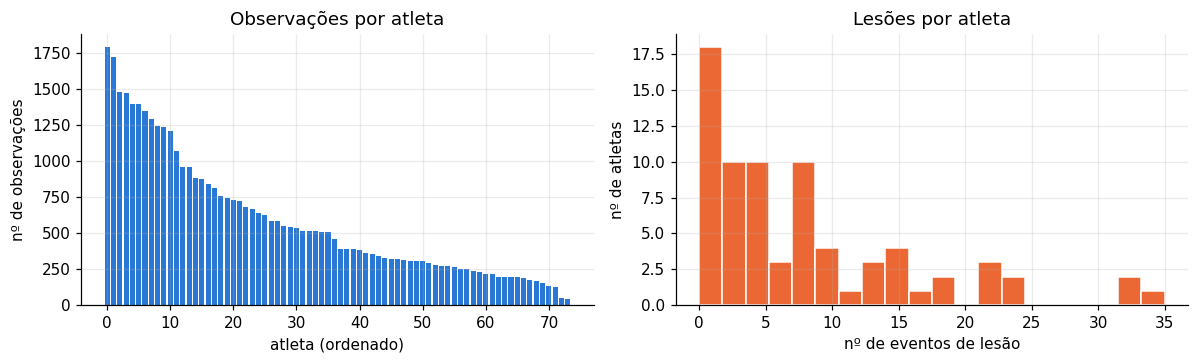

,count,mean,std,min,25%,50%,75%,max
observacoes,74.0000,577.9189,425.9293,43.0000,269.0000,426.5000,753.0000,1791.0000
lesoes,74.0000,7.8784,8.2611,0.0000,2.0000,5.0000,11.5000,35.0000


In [42]:
# Distribuição de observações e lesões por atleta
per_ath = df.groupby(GROUP)[TARGET].agg(observacoes="size", lesoes="sum").sort_values("observacoes", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(range(len(per_ath)), per_ath["observacoes"], color=PALETTE[0], width=0.8)
ax[0].set(title="Observações por atleta", xlabel="atleta (ordenado)", ylabel="nº de observações")
ax[1].hist(per_ath["lesoes"], bins=20, color=PALETTE[1], edgecolor="white")
ax[1].set(title="Lesões por atleta", xlabel="nº de eventos de lesão", ylabel="nº de atletas")
plt.tight_layout(); plt.show()
display(per_ath.describe().T)

#### Pré-processamento

1. Remoção de linhas duplicadas.
2. Conversão de valores sentinela de ausência (se houver) para `NaN`; imputação pela **mediana do treino** (dentro dos *pipelines*, sem vazamento).
3. **Normalização por atleta** (opcional, `ATHLETE_NORM`): cada variável vira o desvio em relação ao histórico do próprio corredor. Não usa o rótulo, mas usa a distribuição de todo o período do atleta — isso é discutido como limitação.
4. Divisão **por atleta**, estratificada: ~20% dos atletas para **teste**, ~20% do restante para **validação** (early stopping e escolha de limiar) e o resto para **treino**.

In [43]:
SEED = 42
ATHLETE_NORM = False
MISSING_SENTINELS = []    # p.ex. [-1] se o dataset codificar ausência com algum valor especial
TEST_SPLITS, VAL_SPLITS = 5, 5   # 1/5 dos atletas → teste; 1/5 do restante → validação
set_seed(SEED)

df = df.drop_duplicates().reset_index(drop=True)
if MISSING_SENTINELS:
    df[FEATURES] = df[FEATURES].replace(MISSING_SENTINELS, np.nan)
if ATHLETE_NORM:
    df = athlete_normalize(df, FEATURES, GROUP)

X_all = df[FEATURES].to_numpy(dtype=np.float32)
y_all = df[TARGET].to_numpy()
g_all = df[GROUP].to_numpy()

idx_rest, idx_test = group_split(y_all, g_all, TEST_SPLITS, SEED)
i_tr, i_va = group_split(y_all[idx_rest], g_all[idx_rest], VAL_SPLITS, SEED)
idx_train, idx_val = idx_rest[i_tr], idx_rest[i_va]

X_tr, y_tr, g_tr = X_all[idx_train], y_all[idx_train], g_all[idx_train]
X_va, y_va, g_va = X_all[idx_val],   y_all[idx_val],   g_all[idx_val]
X_te, y_te, g_te = X_all[idx_test],  y_all[idx_test],  g_all[idx_test]

assert not (set(g_tr) & set(g_va) or set(g_tr) & set(g_te) or set(g_va) & set(g_te)), "atleta em mais de um conjunto!"

split_table = pd.DataFrame({
    s: {"Atletas": len(np.unique(g)), "Observações": len(y), "Lesões": int(y.sum()), "Prevalência (%)": 100 * y.mean()}
    for s, y, g in [("Treino", y_tr, g_tr), ("Validação", y_va, g_va), ("Teste", y_te, g_te)]
}).T
display(split_table)

,Atletas,Observações,Lesões,Prevalência (%)
Treino,48.0000,28184.0000,372.0000,1.3199
Validação,12.0000,6019.0000,81.0000,1.3457
Teste,14.0000,8563.0000,130.0000,1.5182


### 2.4 Hiperparâmetros utilizados

Valores fixados *a priori* (sem busca extensiva, para não sobreajustar ao conjunto de validação, que é pequeno em número de atletas). O desbalanceamento é tratado com **pesos de classe** (LR, RF, XGBoost, MLP) ou **subamostragem** (Bagged XGBoost).

In [44]:
n_pos, n_neg = int(y_tr.sum()), int((y_tr == 0).sum())

HP = {
    "LogisticRegression": dict(C=0.1, class_weight="balanced", max_iter=2000, solver="lbfgs"),
    "RandomForest": dict(n_estimators=300, max_depth=8, min_samples_leaf=20, max_features="sqrt",
                         class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "XGBoost": dict(n_estimators=1500, learning_rate=0.02, max_depth=3, min_child_weight=5,
                    subsample=0.8, colsample_bytree=0.6, reg_lambda=1.0,
                    scale_pos_weight=n_neg / n_pos, tree_method="hist",
                    eval_metric=["logloss", "aucpr", "auc"],   # o último (AUROC) guia o early stopping
                    early_stopping_rounds=150, random_state=SEED, n_jobs=-1),
    "BaggedXGB": dict(n_bags=25, neg_pos_ratio=1.0,
                      xgb_params=dict(n_estimators=250, learning_rate=0.05, max_depth=3, min_child_weight=2,
                                      subsample=0.8, colsample_bytree=0.6, tree_method="hist", n_jobs=-1)),
    "MLP": dict(hidden=[32], dropout=0.5, lr=3e-4, weight_decay=1e-3, batch_size=512,
                epochs=100, patience=20, monitor="AUROC"),
    "TARGET_SPEC": 0.80,   # especificidade-alvo para o limiar de decisão (escolhido na validação)
}
print(json.dumps(HP, indent=2, default=str))

{
  "LogisticRegression": {
    "C": 0.1,
    "class_weight": "balanced",
    "max_iter": 2000,
    "solver": "lbfgs"
  },
  "RandomForest": {
    "n_estimators": 300,
    "max_depth": 8,
    "min_samples_leaf": 20,
    "max_features": "sqrt",
    "class_weight": "balanced_subsample",
    "n_jobs": -1,
    "random_state": 42
  },
  "XGBoost": {
    "n_estimators": 1500,
    "learning_rate": 0.02,
    "max_depth": 3,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.6,
    "reg_lambda": 1.0,
    "scale_pos_weight": 74.76344086021506,
    "tree_method": "hist",
    "eval_metric": [
      "logloss",
      "aucpr",
      "auc"
    ],
    "early_stopping_rounds": 150,
    "random_state": 42,
    "n_jobs": -1
  },
  "BaggedXGB": {
    "n_bags": 25,
    "neg_pos_ratio": 1.0,
    "xgb_params": {
      "n_estimators": 250,
      "learning_rate": 0.05,
      "max_depth": 3,
      "min_child_weight": 2,
      "subsample": 0.8,
      "colsample_bytree": 0.6,
      "tree_me

## 3. Execução

Todos os modelos são treinados no **treino**, monitorados na **validação** (curvas por iteração, early stopping, limiar de decisão) e avaliados **uma única vez** no **teste**.

### 3.1 Baselines — classe majoritária e regressão logística

In [45]:
results, probas = {}, {}   # probabilidades na validação e no teste de cada modelo
MODEL_COLORS = {"Classe majoritária": "#8a8984", "Regressão logística": PALETTE[0], "Random Forest": PALETTE[1],
                "XGBoost": PALETTE[2], "Bagged XGBoost": PALETTE[3], "MLP": PALETTE[4]}

dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
probas["Classe majoritária"] = (dummy.predict_proba(X_va)[:, 1], dummy.predict_proba(X_te)[:, 1])

t0 = time.time()
logreg = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                   ("clf", LogisticRegression(**HP["LogisticRegression"]))]).fit(X_tr, y_tr)
probas["Regressão logística"] = (logreg.predict_proba(X_va)[:, 1], logreg.predict_proba(X_te)[:, 1])
print(f"Regressão logística: {time.time()-t0:.1f}s | AUROC val = {roc_auc_score(y_va, probas['Regressão logística'][0]):.3f}")

Regressão logística: 2.0s | AUROC val = 0.601


### 3.2 Random Forest

Curva por iteração: AUROC/AUPRC de validação em função do número de árvores (avaliado a cada 25 árvores, usando subconjuntos da floresta já treinada).

Random Forest: 19.2s


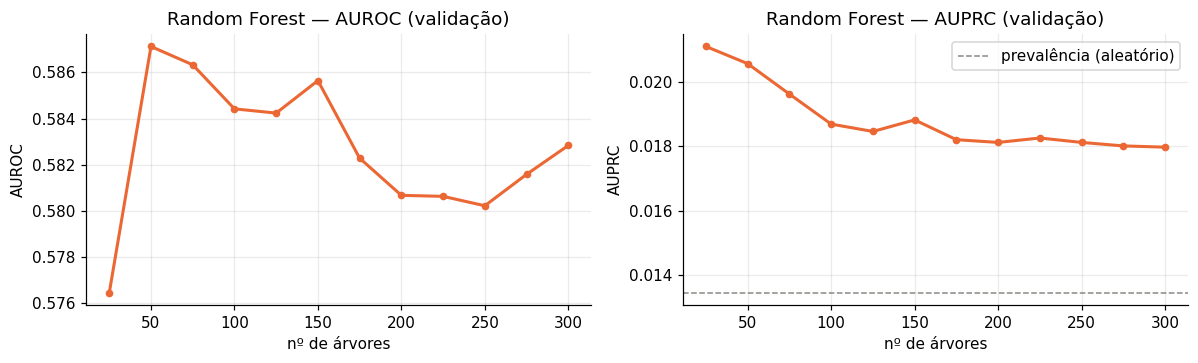

In [46]:
t0 = time.time()
rf = Pipeline([("imp", SimpleImputer(strategy="median")),
               ("clf", RandomForestClassifier(**HP["RandomForest"]))]).fit(X_tr, y_tr)
probas["Random Forest"] = (rf.predict_proba(X_va)[:, 1], rf.predict_proba(X_te)[:, 1])
print(f"Random Forest: {time.time()-t0:.1f}s")

# AUROC/AUPRC conforme o número de árvores cresce
Xv_imp = rf.named_steps["imp"].transform(X_va)
tree_probs = np.array([t.predict_proba(Xv_imp)[:, 1] for t in rf.named_steps["clf"].estimators_])
steps = np.arange(25, len(tree_probs) + 1, 25)
rf_curve = pd.DataFrame([(k, roc_auc_score(y_va, tree_probs[:k].mean(0)), average_precision_score(y_va, tree_probs[:k].mean(0)))
                         for k in steps], columns=["arvores", "AUROC", "AUPRC"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(rf_curve["arvores"], rf_curve["AUROC"], marker="o", ms=4, color=MODEL_COLORS["Random Forest"])
ax[0].set(title="Random Forest — AUROC (validação)", xlabel="nº de árvores", ylabel="AUROC")
ax[1].plot(rf_curve["arvores"], rf_curve["AUPRC"], marker="o", ms=4, color=MODEL_COLORS["Random Forest"])
ax[1].axhline(y_va.mean(), ls="--", color="#8a8984", lw=1, label="prevalência (aleatório)")
ax[1].set(title="Random Forest — AUPRC (validação)", xlabel="nº de árvores", ylabel="AUPRC"); ax[1].legend()
plt.tight_layout(); plt.show()

### 3.3 XGBoost

Curvas de **perda (log-loss)**, **AUROC** e **AUPRC** por iteração de *boosting*, no treino e na validação. O *early stopping* interrompe quando a AUPRC de validação para de melhorar.

XGBoost: 3.8s | melhor iteração = 146


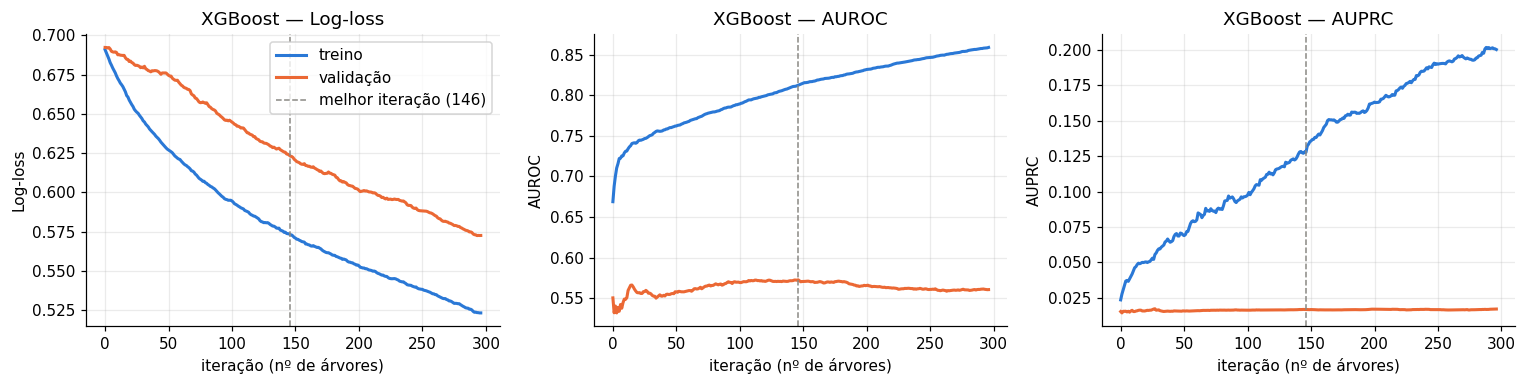

In [47]:
t0 = time.time()
xgb_model = xgb.XGBClassifier(**HP["XGBoost"])
xgb_model.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_va, y_va)], verbose=False)
probas["XGBoost"] = (xgb_model.predict_proba(X_va)[:, 1], xgb_model.predict_proba(X_te)[:, 1])
best_it = xgb_model.best_iteration
print(f"XGBoost: {time.time()-t0:.1f}s | melhor iteração = {best_it}")

ev = xgb_model.evals_result()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, (metric, title) in zip(ax, [("logloss", "Log-loss"), ("auc", "AUROC"), ("aucpr", "AUPRC")]):
    a.plot(ev["validation_0"][metric], label="treino", color=PALETTE[0])
    a.plot(ev["validation_1"][metric], label="validação", color=PALETTE[1])
    a.axvline(best_it, ls="--", color="#8a8984", lw=1, label=f"melhor iteração ({best_it})")
    a.set(title=f"XGBoost — {title}", xlabel="iteração (nº de árvores)", ylabel=title)
ax[0].legend(); plt.tight_layout(); plt.show()

### 3.4 Bagged XGBoost com subamostragem (inspirado em Lövdal et al., 2021)

Cada *bag* treina um XGBoost com **todas as lesões** e uma amostra aleatória de dias sem lesão (razão 1:1). A previsão final é a média das *bags*. Curva por iteração: desempenho de validação conforme *bags* são adicionadas ao ensemble.

Bagged XGBoost: 8.4s


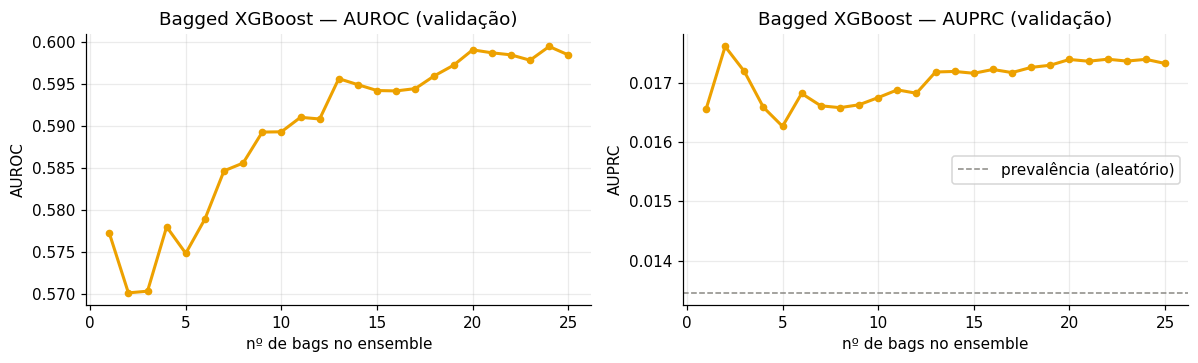

In [48]:
t0 = time.time()
bag = BaggedXGB(HP["BaggedXGB"]["n_bags"], HP["BaggedXGB"]["neg_pos_ratio"], HP["BaggedXGB"]["xgb_params"], seed=SEED)
bag.fit(X_tr, y_tr, X_va, y_va)
probas["Bagged XGBoost"] = (bag.predict_proba(X_va)[:, 1], bag.predict_proba(X_te)[:, 1])
print(f"Bagged XGBoost: {time.time()-t0:.1f}s")

bh = pd.DataFrame(bag.history, columns=["bags", "AUROC", "AUPRC"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(bh["bags"], bh["AUROC"], marker="o", ms=4, color=MODEL_COLORS["Bagged XGBoost"])
ax[0].set(title="Bagged XGBoost — AUROC (validação)", xlabel="nº de bags no ensemble", ylabel="AUROC")
ax[1].plot(bh["bags"], bh["AUPRC"], marker="o", ms=4, color=MODEL_COLORS["Bagged XGBoost"])
ax[1].axhline(y_va.mean(), ls="--", color="#8a8984", lw=1, label="prevalência (aleatório)")
ax[1].set(title="Bagged XGBoost — AUPRC (validação)", xlabel="nº de bags no ensemble", ylabel="AUPRC"); ax[1].legend()
plt.tight_layout(); plt.show()

### 3.5 Rede neural MLP (PyTorch)

MLP com duas camadas ocultas, *BatchNorm*, *dropout* e função de perda **BCE ponderada** (`pos_weight` = negativos/positivos). Curvas de perda (treino e validação) e de AUROC/AUPRC de validação por **época**; o modelo final é o da melhor época (early stopping).

MLP: 3.8s | épocas executadas = 33 | melhor época = 13


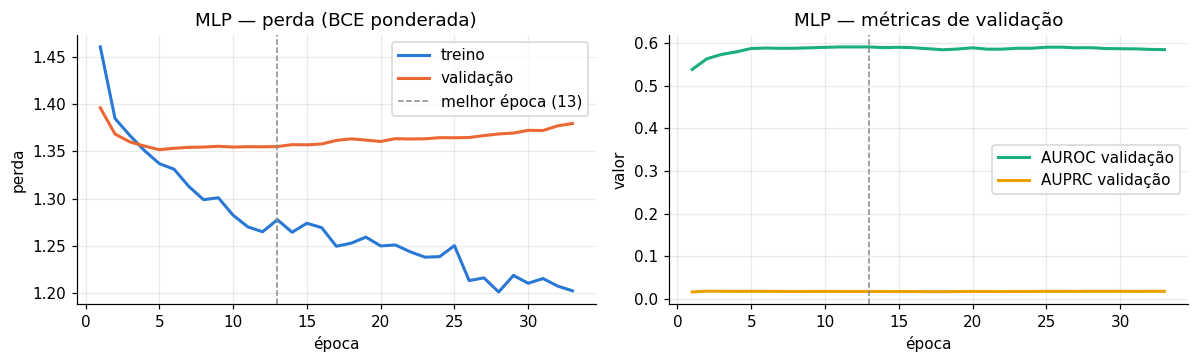

In [49]:
device = "cuda" if torch.cuda.is_available() else "cpu"
prep_nn = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]).fit(X_tr)
Xtr_n, Xva_n, Xte_n = (prep_nn.transform(X).astype(np.float32) for X in (X_tr, X_va, X_te))

t0 = time.time()
mlp, mlp_hist = train_mlp(Xtr_n, y_tr, Xva_n, y_va, HP["MLP"], device, SEED)
probas["MLP"] = (predict_mlp(mlp, Xva_n, device), predict_mlp(mlp, Xte_n, device))
best_ep = int(mlp_hist.loc[mlp_hist[f"val_{HP['MLP']['monitor']}"].idxmax(), "epoch"])
print(f"MLP: {time.time()-t0:.1f}s | épocas executadas = {len(mlp_hist)} | melhor época = {best_ep}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(mlp_hist["epoch"], mlp_hist["train_loss"], label="treino", color=PALETTE[0])
ax[0].plot(mlp_hist["epoch"], mlp_hist["val_loss"], label="validação", color=PALETTE[1])
ax[0].axvline(best_ep, ls="--", color="#8a8984", lw=1, label=f"melhor época ({best_ep})")
ax[0].set(title="MLP — perda (BCE ponderada)", xlabel="época", ylabel="perda"); ax[0].legend()
ax[1].plot(mlp_hist["epoch"], mlp_hist["val_AUROC"], label="AUROC validação", color=PALETTE[2])
ax[1].plot(mlp_hist["epoch"], mlp_hist["val_AUPRC"], label="AUPRC validação", color=PALETTE[3])
ax[1].axvline(best_ep, ls="--", color="#8a8984", lw=1)
ax[1].set(title="MLP — métricas de validação", xlabel="época", ylabel="valor"); ax[1].legend()
plt.tight_layout(); plt.show()

### 3.6 Medidas de desempenho no conjunto de teste

- **AUROC** (métrica principal) e **AUPRC** (mais informativa sob forte desbalanceamento; o valor de referência de um classificador aleatório é a prevalência).
- **Lift da AUPRC** = AUPRC ÷ prevalência
- Sensibilidade, especificidade, precisão e F1 no **limiar de Youden escolhido na validação** (o teste não é usado para escolher o limiar).
- IC 95% da AUROC por *bootstrap* de atletas.

In [50]:
rows = []
for name, (p_va, p_te) in probas.items():
    thr = threshold_at_specificity(y_va, p_va, HP["TARGET_SPEC"]) if name != "Classe majoritária" else 0.5
    r = evaluate(y_te, p_te, thr)
    lo, hi = cluster_bootstrap_ci(y_te, p_te, g_te, roc_auc_score, n_boot=1000, seed=SEED)
    r["AUROC IC95%"] = f"[{lo:.3f}; {hi:.3f}]"
    r["AUROC validação"] = roc_auc_score(y_va, p_va)
    rows.append(pd.Series(r, name=name))
metrics_test = pd.DataFrame(rows)
cols = ["AUROC", "AUROC IC95%", "AUPRC", "Lift AUPRC", "Sensibilidade", "Especificidade", "Precisão (VPP)", "F1",
        "Limiar", "TP", "FP", "FN", "TN", "AUROC validação"]
metrics_test = metrics_test[cols]
print(f"Prevalência no teste: {y_te.mean():.4f} (AUPRC de um classificador aleatório)")
display(metrics_test.style.format(precision=3).highlight_max(subset=["AUROC", "AUPRC", "F1"], color="#cde2fb"))

Prevalência no teste: 0.0152 (AUPRC de um classificador aleatório)


,AUROC,AUROC IC95%,AUPRC,Lift AUPRC,Sensibilidade,Especificidade,Precisão (VPP),F1,Limiar,TP,FP,FN,TN,AUROC validação
Classe majoritária,0.500,[0.500; 0.500],0.015,1.000,0.000,1.000,0.000,0.000,0.500,0,0,130,8433,0.500
Regressão logística,0.616,[0.555; 0.691],0.024,1.557,0.254,0.835,0.023,0.043,0.620,33,1388,97,7045,0.601
Random Forest,0.580,[0.529; 0.650],0.020,1.320,0.223,0.849,0.022,0.040,0.427,29,1276,101,7157,0.583
XGBoost,0.593,[0.537; 0.663],0.022,1.426,0.238,0.837,0.022,0.040,0.564,31,1378,99,7055,0.573
Bagged XGBoost,0.666,[0.597; 0.736],0.031,2.025,0.308,0.852,0.031,0.056,0.649,40,1251,90,7182,0.598
MLP,0.621,[0.550; 0.696],0.026,1.719,0.331,0.835,0.030,0.055,0.600,43,1392,87,7041,0.591


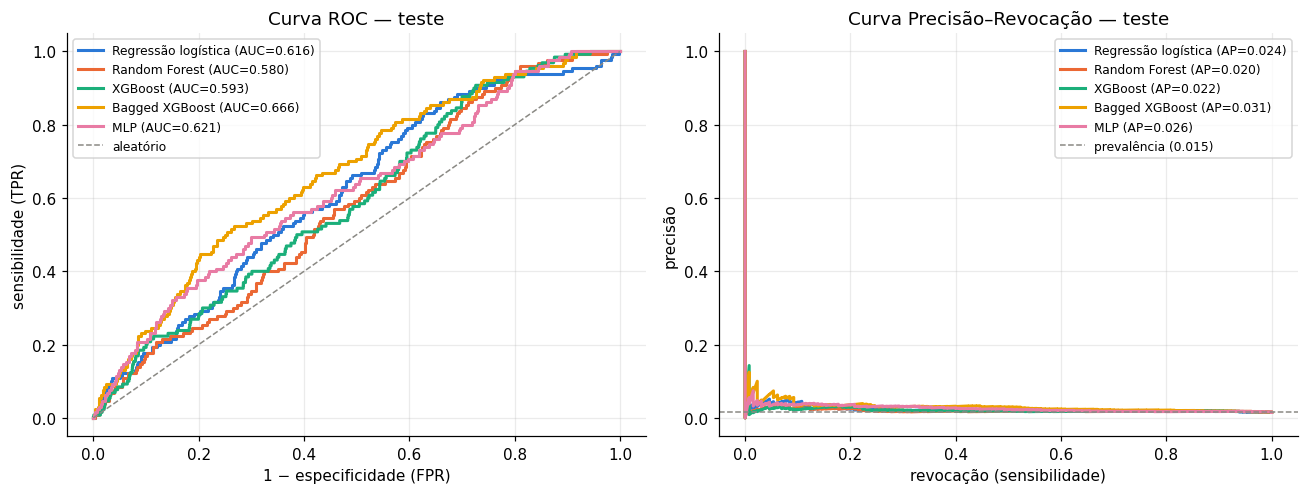

In [51]:
# Curvas ROC e Precisão-Revocação no teste
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for name, (_, p_te) in probas.items():
    if name == "Classe majoritária":
        continue
    fpr, tpr, _ = roc_curve(y_te, p_te)
    prec, rec, _ = precision_recall_curve(y_te, p_te)
    c = MODEL_COLORS[name]
    ax[0].plot(fpr, tpr, color=c, label=f"{name} (AUC={roc_auc_score(y_te, p_te):.3f})")
    ax[1].plot(rec, prec, color=c, label=f"{name} (AP={average_precision_score(y_te, p_te):.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", color="#8a8984", lw=1, label="aleatório")
ax[0].set(title="Curva ROC — teste", xlabel="1 − especificidade (FPR)", ylabel="sensibilidade (TPR)")
ax[1].axhline(y_te.mean(), ls="--", color="#8a8984", lw=1, label=f"prevalência ({y_te.mean():.3f})")
ax[1].set(title="Curva Precisão–Revocação — teste", xlabel="revocação (sensibilidade)", ylabel="precisão")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

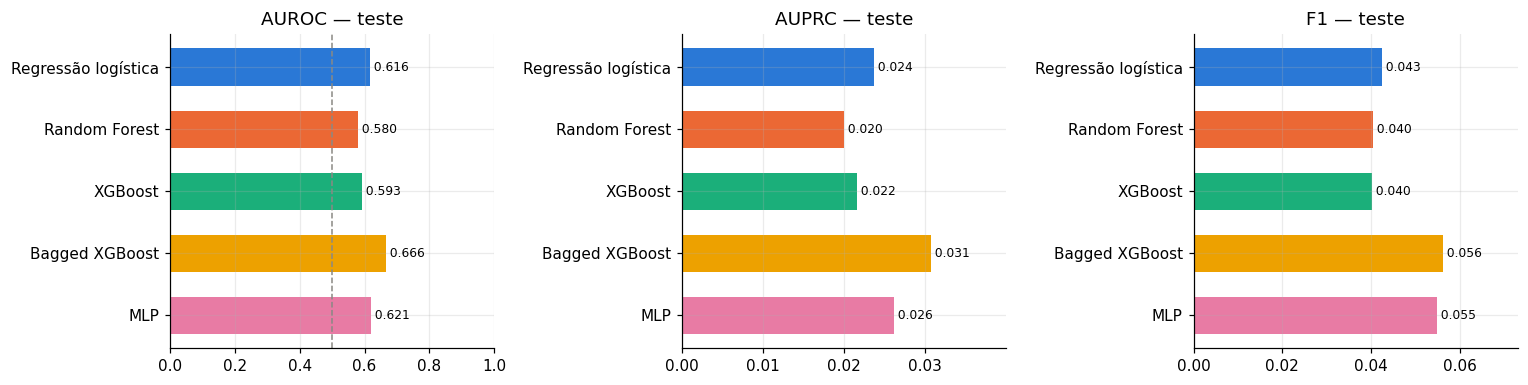

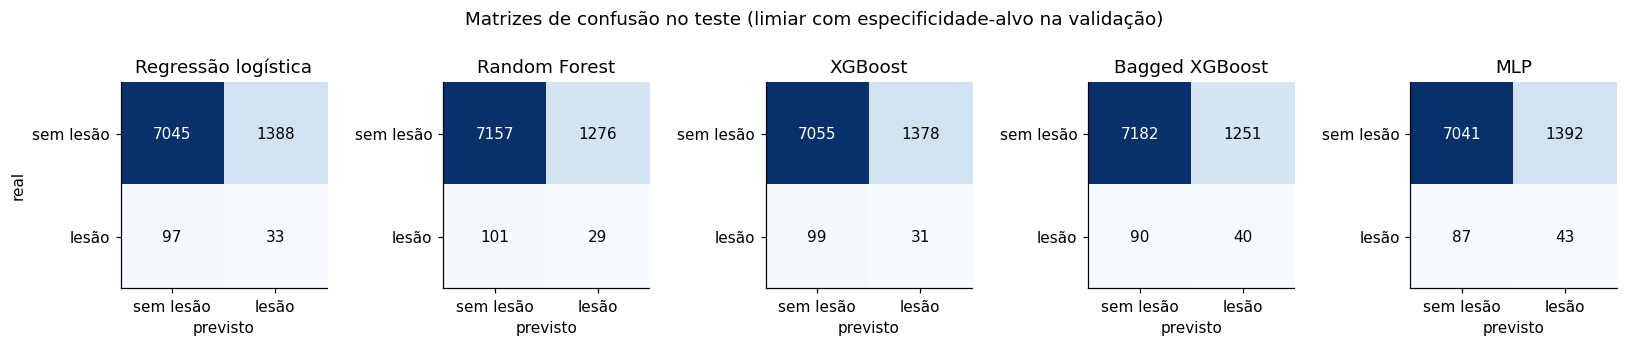

In [52]:
# Comparação das métricas principais e matrizes de confusão
models_plot = [m for m in probas if m != "Classe majoritária"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, met in zip(ax, ["AUROC", "AUPRC", "F1"]):
    vals = metrics_test.loc[models_plot, met].astype(float)
    a.barh(models_plot, vals, color=[MODEL_COLORS[m] for m in models_plot], height=0.6)
    for i, v in enumerate(vals): a.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    a.set(title=f"{met} — teste", xlim=(0, max(1.0 if met == "AUROC" else vals.max() * 1.3, 0.01)))
    if met == "AUROC": a.axvline(0.5, ls="--", color="#8a8984", lw=1)
    a.invert_yaxis()
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, len(models_plot), figsize=(3 * len(models_plot), 2.9))
for a, m in zip(ax, models_plot):
    r = metrics_test.loc[m]; cm = np.array([[r.TN, r.FP], [r.FN, r.TP]], dtype=int)
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for (i, j), v in np.ndenumerate(cm):
        a.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    a.set(title=m, xticks=[0, 1], yticks=[0, 1], xticklabels=["sem lesão", "lesão"], yticklabels=["sem lesão", "lesão"],
          xlabel="previsto", ylabel="real" if m == models_plot[0] else "")
plt.suptitle("Matrizes de confusão no teste (limiar com especificidade-alvo na validação)", y=1.03); plt.tight_layout(); plt.show()

### 3.7 Validação cruzada agrupada por atleta (robustez)

Como o teste contém poucos atletas, a estimativa de um único *split* é ruidosa. Aqui repetimos a avaliação com **validação cruzada estratificada e agrupada por atleta (5 folds)** sobre todo o dataset, usando os mesmos hiperparâmetros (XGBoost com o nº de árvores encontrado no early stopping).

O fold 1 é o mesmo conjunto do teste e que a média da validação cruzada é a estimativa principal.

fold 1/5 concluído (25s)
fold 2/5 concluído (48s)
fold 3/5 concluído (72s)
fold 4/5 concluído (101s)
fold 5/5 concluído (125s)


AUROC         AUPRC        Lift AUPRC       
                      mean    std   mean    std       mean    std
modelo                                                           
Bagged XGBoost      0.6369 0.0297 0.0225 0.0079     1.6431 0.2139
Random Forest       0.5925 0.0269 0.0187 0.0068     1.3750 0.1638
Regressão logística 0.6139 0.0306 0.0208 0.0062     1.5504 0.1357
XGBoost             0.5939 0.0423 0.0214 0.0094     1.5499 0.4783

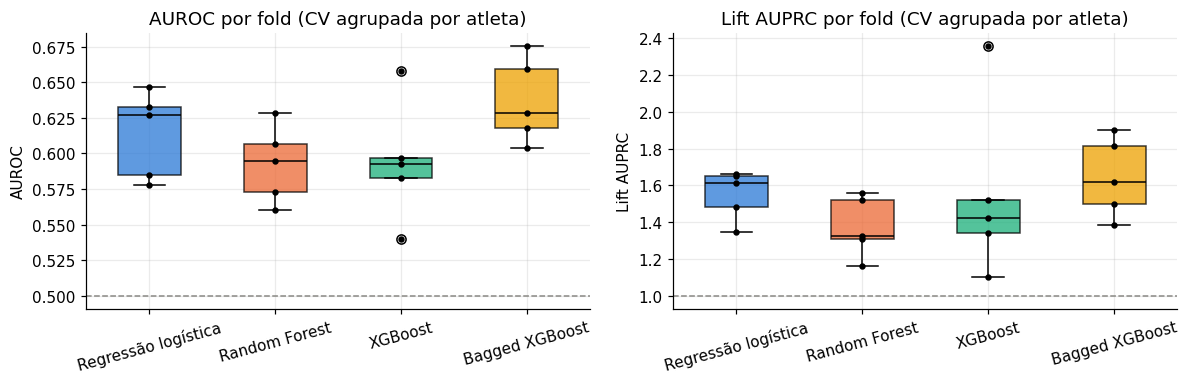

In [53]:
CV_FOLDS = 5

def make_models(y_train):
    return {
        "Regressão logística": Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                                         ("clf", LogisticRegression(**HP["LogisticRegression"]))]),
        "Random Forest": Pipeline([("imp", SimpleImputer(strategy="median")), ("clf", RandomForestClassifier(**HP["RandomForest"]))]),
        "Bagged XGBoost": BaggedXGB(HP["BaggedXGB"]["n_bags"], HP["BaggedXGB"]["neg_pos_ratio"], HP["BaggedXGB"]["xgb_params"], seed=SEED),
    }

cv_rows = []
sgkf = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
t0 = time.time()
for fold, (tr, te) in enumerate(sgkf.split(X_all, y_all, g_all), 1):
    fitted = make_models(y_all[tr])
    # XGBoost: early stopping DENTRO do fold (validação interna por atleta), sem usar dados de outros folds
    itr, iva = group_split(y_all[tr], g_all[tr], VAL_SPLITS, SEED)
    tr_in, va_in = tr[itr], tr[iva]
    spw = (y_all[tr_in] == 0).sum() / max(y_all[tr_in].sum(), 1)
    m_xgb = xgb.XGBClassifier(**{**HP["XGBoost"], "scale_pos_weight": spw})
    m_xgb.fit(X_all[tr_in], y_all[tr_in], eval_set=[(X_all[va_in], y_all[va_in])], verbose=False)
    for name, model in fitted.items():
        model.fit(X_all[tr], y_all[tr])
    fitted["XGBoost"] = m_xgb
    for name, model in fitted.items():
        p = model.predict_proba(X_all[te])[:, 1]
        cv_rows.append({"fold": fold, "modelo": name, "AUROC": roc_auc_score(y_all[te], p),
                        "AUPRC": average_precision_score(y_all[te], p), "prevalência": y_all[te].mean(),
                        "melhor_iteracao_xgb": m_xgb.best_iteration if name == "XGBoost" else np.nan})
    print(f"fold {fold}/{CV_FOLDS} concluído ({time.time()-t0:.0f}s)")
cv_results = pd.DataFrame(cv_rows)
cv_results["Lift AUPRC"] = cv_results["AUPRC"] / cv_results["prevalência"]
cv_summary = cv_results.groupby("modelo")[["AUROC", "AUPRC", "Lift AUPRC"]].agg(["mean", "std"])
display(cv_summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
names = ["Regressão logística", "Random Forest", "XGBoost", "Bagged XGBoost"]
for a, met in zip(ax, ["AUROC", "Lift AUPRC"]):
    data = [cv_results.loc[cv_results.modelo == n, met] for n in names]
    bp = a.boxplot(data, patch_artist=True, widths=0.5, medianprops=dict(color="black"))
    for patch, n in zip(bp["boxes"], names): patch.set_facecolor(MODEL_COLORS[n]); patch.set_alpha(0.75)
    for i, d in enumerate(data, 1): a.scatter(np.full(len(d), i), d, color="black", s=10, zorder=3)
    a.set_xticks(range(1, len(names) + 1)); a.set_xticklabels(names, rotation=15)
    a.set(title=f"{met} por fold (CV agrupada por atleta)", ylabel=met)
ax[0].axhline(0.5, ls="--", color="#8a8984", lw=1); ax[1].axhline(1.0, ls="--", color="#8a8984", lw=1)
plt.tight_layout(); plt.show()

### 3.8 Importância das variáveis (XGBoost)

Importância por *gain*, individual e **agregada por variável de origem** (somando os lags — p.ex. `total km`, `total km.1`, …, `total km.6` → `total km`) e **por defasagem temporal** (dia/semana anterior).

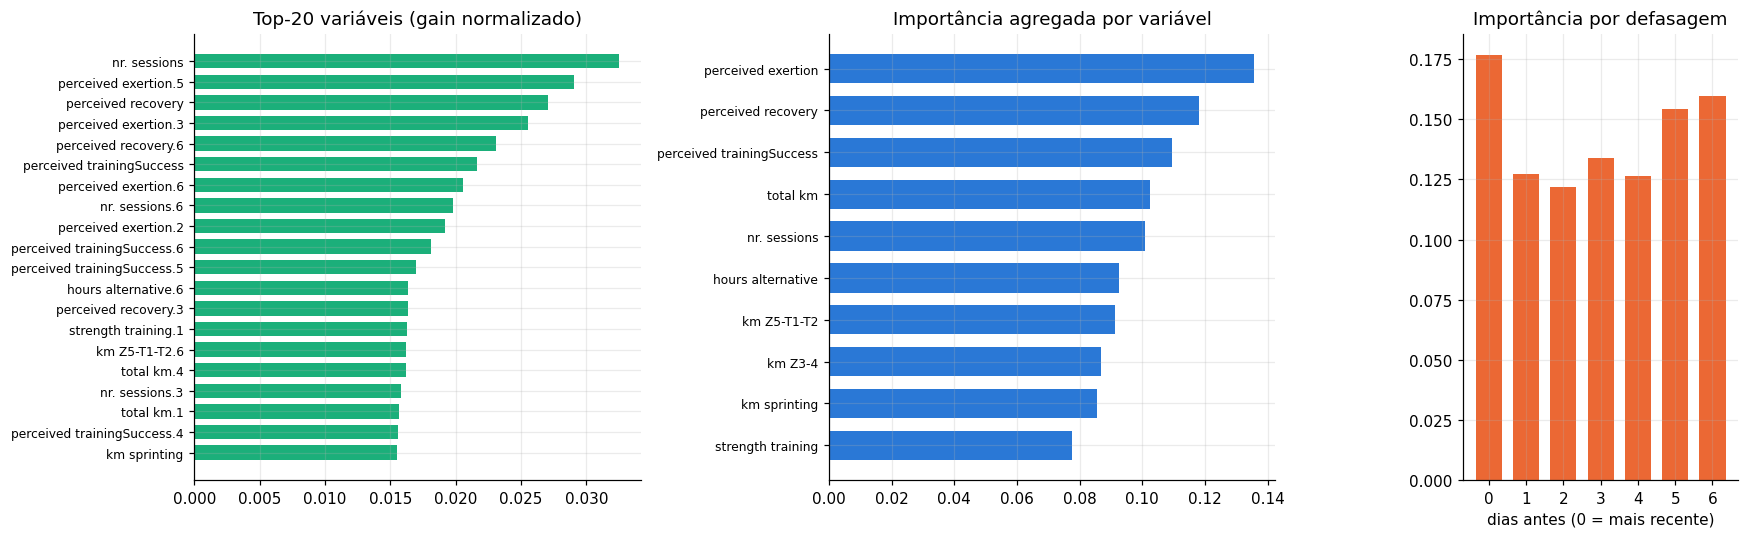

In [54]:
imp = pd.Series(xgb_model.get_booster().get_score(importance_type="gain"))
imp.index = [FEATURES[int(k[1:])] if re.fullmatch(r"f\d+", k) else k for k in imp.index]
imp = imp.reindex(FEATURES).fillna(0)
imp = imp / imp.sum()

base = imp.groupby(lambda c: re.sub(r"\.\d+$", "", c)).sum().sort_values()
lag  = imp.groupby(lambda c: int(re.search(r"\.(\d+)$", c).group(1)) if re.search(r"\.(\d+)$", c) else 0).sum().sort_index()
lag_label = "dias antes (0 = mais recente)" if APPROACH == "day" else "semanas antes (0 = mais recente)"

fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.3, 1.3, 0.8]})
top = imp.sort_values().tail(20)
ax[0].barh(top.index, top.values, color=PALETTE[2], height=0.7); ax[0].set(title="Top-20 variáveis (gain normalizado)")
ax[1].barh(base.index, base.values, color=PALETTE[0], height=0.7); ax[1].set(title="Importância agregada por variável")
ax[2].bar(lag.index.astype(str), lag.values, color=PALETTE[1], width=0.7); ax[2].set(title="Importância por defasagem", xlabel=lag_label)
for a in ax[:2]: a.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

### 3.9 Exportação dos resultados

Salva tabelas em `results/` para uso no `README.md` (seções *Avaliação* e *Conclusão*).

In [55]:
TAG = f"{APPROACH}_{'normatleta' if ATHLETE_NORM else 'semnorm'}"

out = Path("results"); out.mkdir(exist_ok=True)
split_table.to_csv(out / f"splits_{TAG}.csv")
metrics_test.to_csv(out / f"metricas_teste_{TAG}.csv")
cv_results.to_csv(out / f"cv_folds_{TAG}.csv", index=False)
cv_summary.to_csv(out / f"cv_resumo_{TAG}.csv")
pd.DataFrame(ev["validation_1"]).to_csv(out / f"xgb_curvas_validacao_{TAG}.csv", index_label="iteracao")
mlp_hist.to_csv(out / f"mlp_historico_{TAG}.csv", index=False)
with open(out / f"hiperparametros_{TAG}.json", "w") as f: json.dump(HP, f, indent=2, default=str)
print("Arquivos salvos:", sorted(p.name for p in out.iterdir()))

Arquivos salvos: ['cv_folds_day_normatleta.csv', 'cv_folds_day_semnorm.csv', 'cv_resumo_day_normatleta.csv', 'cv_resumo_day_semnorm.csv', 'hiperparametros_day_normatleta.json', 'hiperparametros_day_semnorm.json', 'metricas_teste_day_normatleta.csv', 'metricas_teste_day_semnorm.csv', 'mlp_historico_day_normatleta.csv', 'mlp_historico_day_semnorm.csv', 'splits_day_normatleta.csv', 'splits_day_semnorm.csv', 'xgb_curvas_validacao_day_normatleta.csv', 'xgb_curvas_validacao_day_semnorm.csv']
